In [1]:
library(readxl)
library(IRdisplay)

todays_date <- format(Sys.Date(), "%Y-%m-%d")
student_id <- "johhun3213"

file_path <- "C:/Users/david/OneDrive/Desktop/ECPI/SDC380/PA2.5/AirBnBSummary_v2_cleaned.xlsx"
df_new <- read_excel(file_path)

display_markdown(paste("###", student_id, "-", todays_date))

total_listings <- nrow(df_new)

min_price <- min(df_new$price, na.rm = TRUE)

max_price <- max(df_new$price, na.rm = TRUE)

mean_price <- mean(df_new$price, na.rm = TRUE)

median_reviews <- median(df_new$number_of_reviews, na.rm = TRUE)

std_price <- sd(df_new$price, na.rm = TRUE)

correlation_between_price_availability <- cor(df_new$price, df_new$`availability_365`, use = "pairwise.complete.obs")

print(paste("Total Count of Listings:", total_listings))
print(paste("Minimum Price:", min_price))
print(paste("Maximum Price:", max_price))
print(paste("Mean Price:", mean_price))
print(paste("Median Reviews:", median_reviews))
print(paste("Standard Deviation of Price:", std_price))
print(paste("Correlation Between the Price and Availability:", correlation_between_price_availability))

### johhun3213 - 2026-10-18

[1] "Total Count of Listings: 1397"
[1] "Minimum Price: 25"
[1] "Maximum Price: 489"
[1] "Mean Price: 142.879742304939"
[1] "Median Reviews: 23"
[1] "Standard Deviation of Price: 80.9385215270347"
[1] "Correlation Between the Price and Availability: 0.119528468865211"


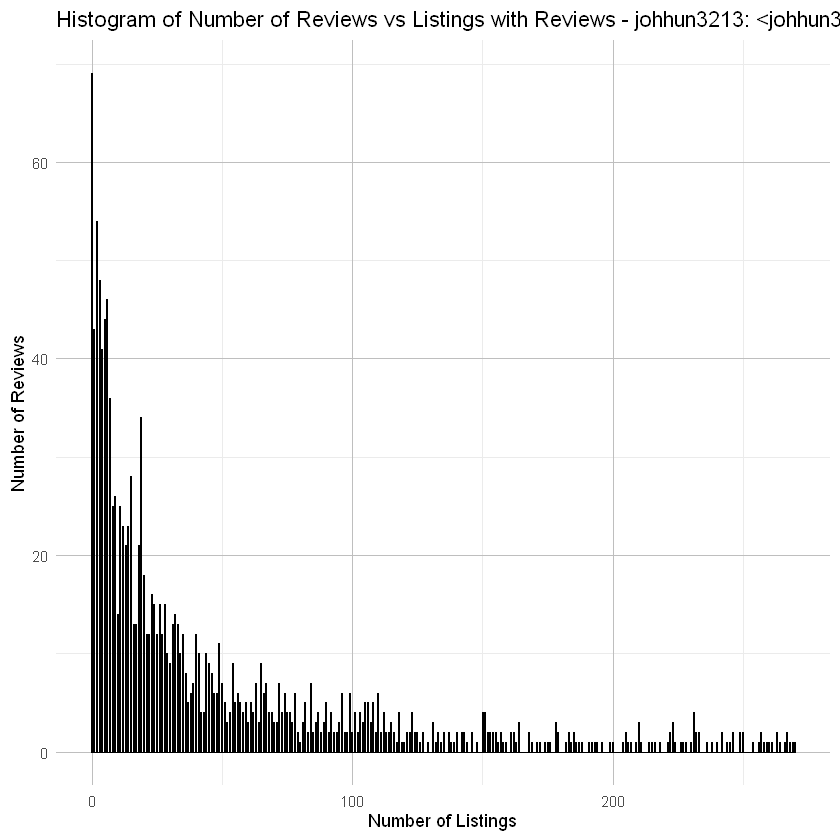

In [4]:
library(readxl)
library(ggplot2)
library(dplyr)
library(corrplot)

student_id <- "<johhun3213>"

file_path <- "C:/Users/david/OneDrive/Desktop/ECPI/SDC380/PA2.5/AirBnBSummary_v2_cleaned.xlsx"
df_new <- read_excel(file_path)

current_datetime <- format(Sys.time(), "%Y-%m-%d %H:%M:%S")

ggplot(df_new, aes(x = number_of_reviews)) + geom_histogram(binwidth = 0.2, fill = "skyblue", color = "black") + 
    xlab("Number of Listings") + 
    ylab("Number of Reviews") +
    ggtitle(paste("Histogram of Number of Reviews vs Listings with Reviews - johhun3213:", student_id, "-", current_datetime)) +
    theme_minimal() + theme(panel.grid.major = element_line(colour = "grey"))

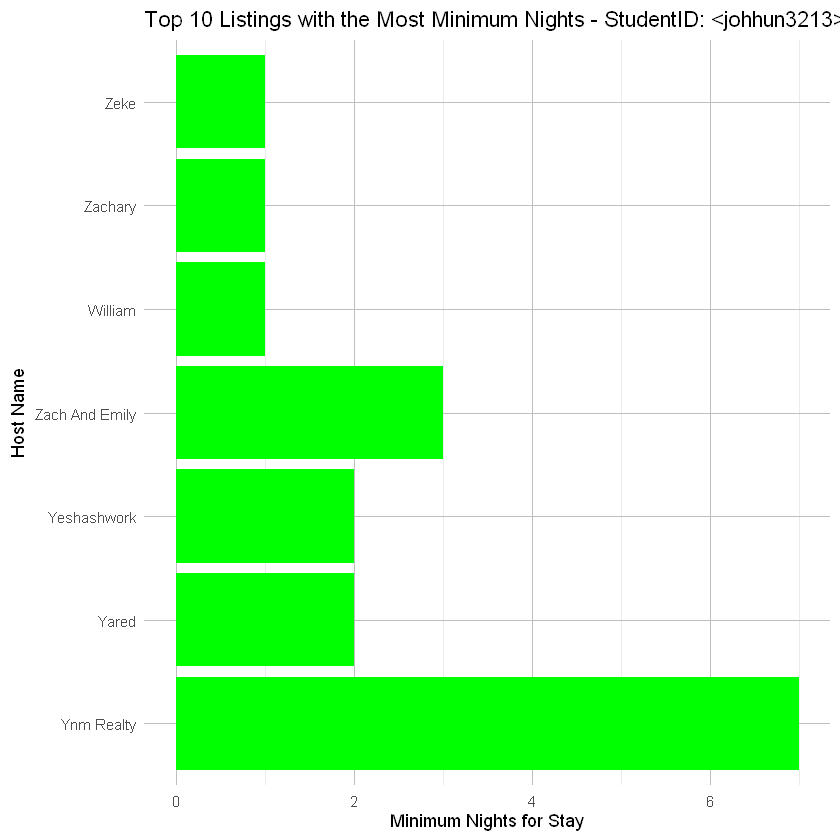

In [12]:
student_id <- "<johhun3213>"

file_path <- "C:/Users/david/OneDrive/Desktop/ECPI/SDC380/PA2.5/AirBnBSummary_v2_cleaned.xlsx"
df_new <- read_excel(file_path)

current_datetime <- format(Sys.time(), "%Y-%m-%d %H:%M:%S")

top_10_minimum_nights <- df_new %>% arrange(desc(minimum_nights)) %>% head(10)

ggplot(top_10_minimum_nights, aes(x = reorder(`host_name`, -minimum_nights), y = minimum_nights)) +
    geom_bar(stat = "identity", fill = "green") +
    xlab("Host Name") +
    ylab("Minimum Nights for Stay") +
    ggtitle(paste("Top 10 Listings with the Most Minimum Nights - StudentID:", student_id, "-", current_datetime)) +
    coord_flip() +
    theme_minimal() +
    theme(panel.grid.major = element_line(colour = "grey"))

`geom_smooth()` using formula = 'y ~ x'
Warning message in plot_theme(plot):
"The `Legend.title` theme element is not defined in the element hierarchy."


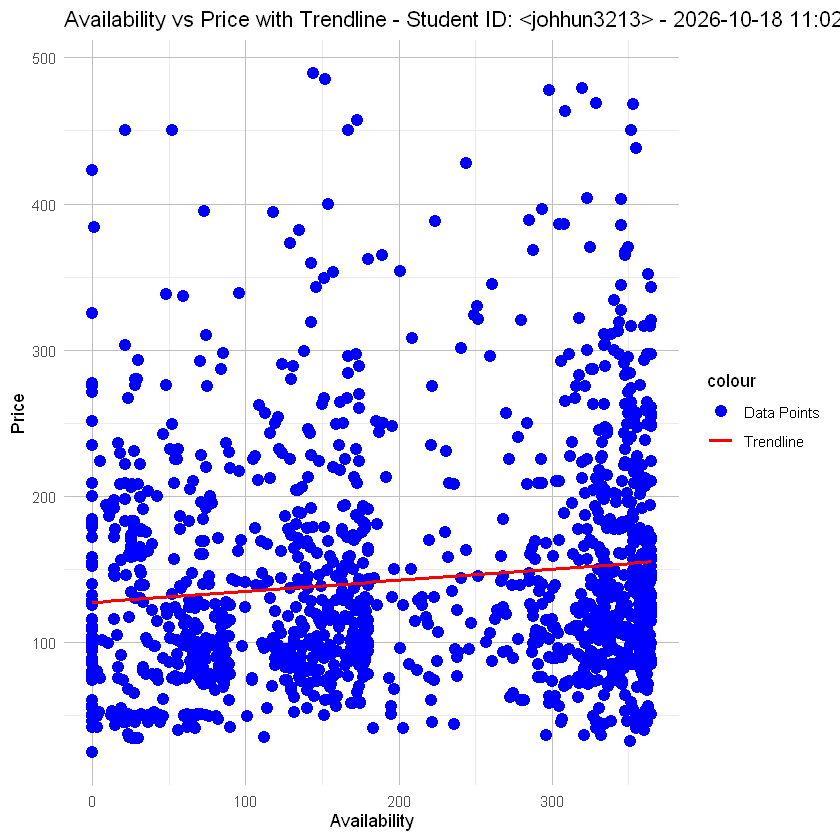

In [13]:
student_id <- "<johhun3213>"

file_path <- "C:/Users/david/OneDrive/Desktop/ECPI/SDC380/PA2.5/AirBnBSummary_v2_cleaned.xlsx"
df_new <- read_excel(file_path)

current_datetime <- format(Sys.time(), "%Y-%m-%d %H:%M:%S")

ggplot(df_new, aes(x = `availability_365`, y = price)) +
    geom_point(aes(color = "Data Points"), size = 3) +
    geom_smooth(method = "lm", se = FALSE, aes(color = "Trendline")) +
    scale_color_manual(values = c("Data Points" = "blue", "Trendline" = "red")) +
    xlab("Availability") +
    ylab("Price") +
    ggtitle(paste("Availability vs Price with Trendline - Student ID:", student_id, "-", current_datetime)) +
    theme_minimal() +
    theme(panel.grid.major = element_line(colour = "grey")) +
    theme(Legend.title = element_blank())

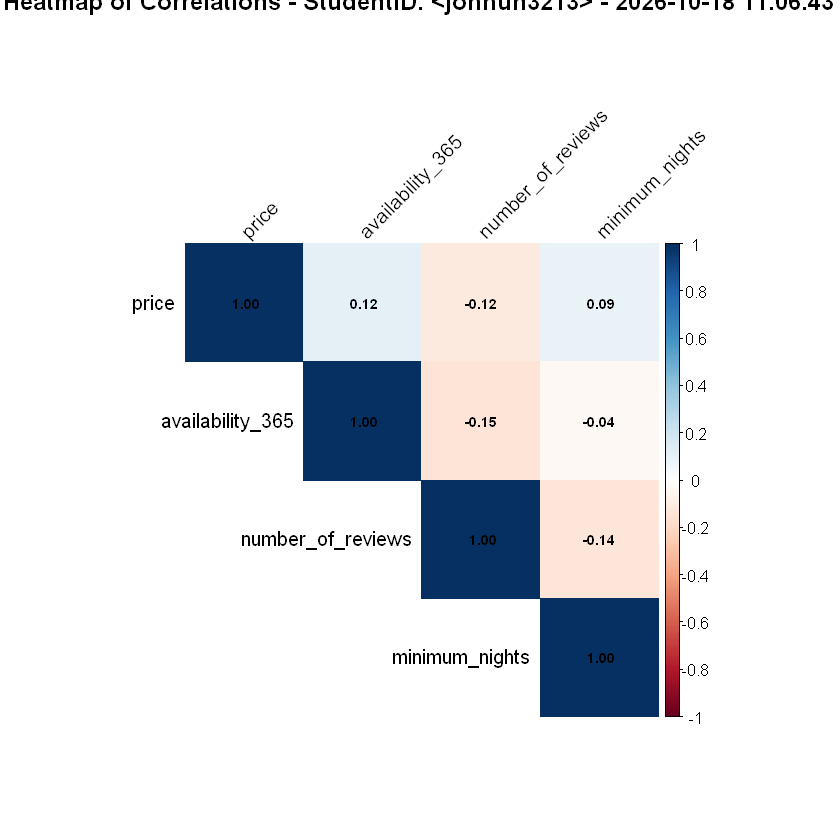

In [14]:
student_id <- "<johhun3213>"

file_path <- "C:/Users/david/OneDrive/Desktop/ECPI/SDC380/PA2.5/AirBnBSummary_v2_cleaned.xlsx"
df_new <- read_excel(file_path)

current_datetime <- format(Sys.time(), "%Y-%m-%d %H:%M:%S")

selected_columns <- df_new %>% select(price, `availability_365`, `number_of_reviews`, minimum_nights)

correlation_matrix <- cor(selected_columns, use = "pairwise.complete.obs")

corrplot(correlation_matrix, method = "color", type = "upper", title = paste("Heatmap of Correlations - StudentID:", student_id, "-", current_datetime),
        tl.col = "black", tl.srt = 45, number.cex = 0.7, addCoef.col = "black")